# GOAL: Pixel-level masks on satellite pictures of houses

- Use the pixel-level results from the SAM model (lots of overlapping predictions) by checking which ones "agree" with the satellite-building-segmentation labels.
- "Agree" means a Jaccard index (IoU, intersection over union) above 0.3 between a SAM mask and a labelled building box.
- Then prompt SAM with the labelled boxes themselves: one mask per building. This is how SAM turns cheap box labels into pixel masks.

**Runs on a CPU** in the course container (`pytorch` image), in a few minutes. It needs the network: it downloads three labelled images (the dataset's `mini` split, about 150 KB) and the smallest SAM model, ViT-B (375 MB).
On a GPU (in Colab: Runtime, Change runtime type, T4 GPU) it uses the largest model, ViT-H (2.5 GB), as the original notebook did.

Outside the course container: `pip install torch torchvision datasets segment-anything matplotlib`.

In [1]:
import os

import matplotlib.patches as patches
import matplotlib.pyplot as plt
import numpy as np
import torch

# COURSE_SMOKE=1 (the course smoke test) asks SAM for fewer masks, so the run is shorter
SMOKE = os.environ.get("COURSE_SMOKE") == "1"
device = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", device)

Device: cpu


**Load the satellite dataset**

In [2]:
from datasets import load_dataset

# From https://huggingface.co/datasets/keremberke/satellite-building-segmentation
# The dataset's own loading script no longer runs (datasets 4 and later), so read the
# Parquet copy that Hugging Face keeps of it: the "mini" split has three 500x500 images.
PARQUET = "hf://datasets/keremberke/satellite-building-segmentation@refs%2Fconvert%2Fparquet/"
ds = load_dataset("parquet", data_files={"train": PARQUET + "mini/train/0000.parquet"})
# The third image: five separate houses, and fewer trees over the roofs than in the other two
example = ds["train"][2]
print(example.keys())
example["objects"]["bbox"]

dict_keys(['image_id', 'image', 'width', 'height', 'objects'])


[[358.0, 0.0, 61.52000045776367, 55.970001220703125],
 [449.0, 1.0, 51.0, 37.959999084472656],
 [174.0, 265.0, 167.02999877929688, 235.3800048828125],
 [161.0, 0.0, 76.5, 93.0999984741211],
 [256.0, 0.0, 70.0999984741211, 74.9000015258789]]

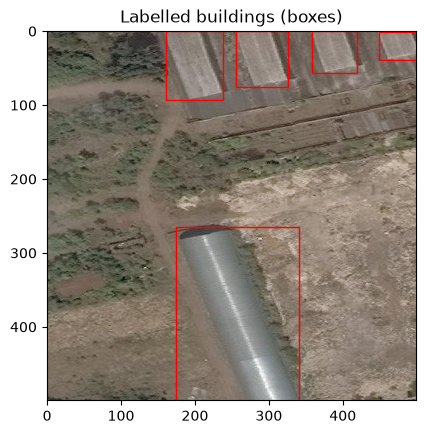

In [3]:
image = example["image"].convert("RGB")

fig, ax = plt.subplots(1)
ax.imshow(image)
ax.set_title("Labelled buildings (boxes)")

for bbox in example["objects"]["bbox"]:
    x_min, y_min, width, height = bbox
    rect = patches.Rectangle((x_min, y_min), width, height, linewidth=1, edgecolor='r', facecolor='none')
    ax.add_patch(rect)

plt.show()

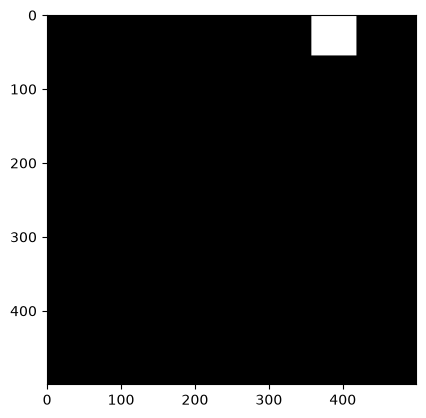

In [4]:
def make_mask(labelled_bbox, image):
    """A binary mask (rows = y, columns = x) that is 1 inside a labelled box."""
    x_min, y_min, width, height = (int(v) for v in labelled_bbox)
    mask = np.zeros((image.height, image.width))
    mask[y_min:y_min + height, x_min:x_min + width] = 1
    return mask


mask_instance = make_mask(example["objects"]["bbox"][0], image)
plt.imshow(mask_instance, cmap='gray')
plt.show()

**Load SAM (Segment Anything)**

The automatic mask generator prompts SAM with a grid of points over the image and keeps the good masks.

In [5]:
# From: https://github.com/facebookresearch/segment-anything/blob/main/notebooks/automatic_mask_generator_example.ipynb
from segment_anything import sam_model_registry, SamAutomaticMaskGenerator

# ViT-H (2.5 GB) on a GPU; the smallest model, ViT-B (375 MB), on a CPU
if device == "cuda" and not SMOKE:
    model_type, sam_checkpoint = "vit_h", "sam_vit_h_4b8939.pth"
else:
    model_type, sam_checkpoint = "vit_b", "sam_vit_b_01ec64.pth"

if not os.path.exists(sam_checkpoint):
    torch.hub.download_url_to_file(
        "https://dl.fbaipublicfiles.com/segment_anything/" + sam_checkpoint, sam_checkpoint, progress=False)

sam = sam_model_registry[model_type](checkpoint=sam_checkpoint)
sam.to(device=device)

# A 32x32 grid of point prompts is SAM's default; 8x8 is enough for a smoke test
mask_generator = SamAutomaticMaskGenerator(sam, points_per_side=8 if SMOKE else 32)

In [6]:
def show_anns(anns):
    if len(anns) == 0:
        return
    sorted_anns = sorted(anns, key=(lambda x: x['area']), reverse=True)
    ax = plt.gca()
    ax.set_autoscale_on(False)
    img = np.ones((sorted_anns[0]['segmentation'].shape[0], sorted_anns[0]['segmentation'].shape[1], 4))
    img[:, :, 3] = 0
    for ann in sorted_anns:
        m = ann['segmentation']
        color_mask = np.concatenate([np.random.random(3), [0.35]])
        img[m] = color_mask
    ax.imshow(img)

In [7]:
masks = mask_generator.generate(np.array(image))
print(len(masks), "masks")
print(masks[0].keys())

32 masks
dict_keys(['segmentation', 'area', 'bbox', 'predicted_iou', 'point_coords', 'stability_score', 'crop_box'])


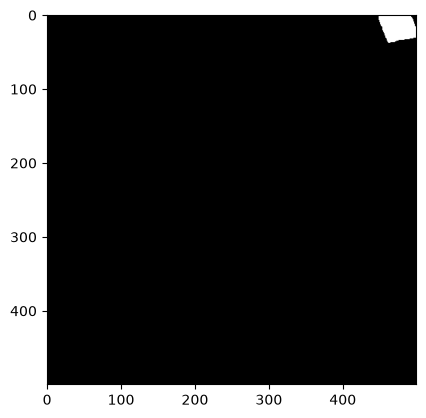

In [8]:
binary_array = masks[0]['segmentation'].astype(int)
plt.imshow(binary_array, cmap='gray')
plt.show()

In [9]:
for m in masks:
    print(m['bbox'])

[449.0, 0.0, 50.0, 37.0]
[358.0, 0.0, 60.0, 54.0]
[180.0, 262.0, 66.0, 19.0]
[0.0, 0.0, 160.0, 71.0]
[257.0, 0.0, 67.0, 74.0]
[175.0, 223.0, 32.0, 21.0]
[160.0, 0.0, 76.0, 91.0]
[16.0, 327.0, 62.0, 32.0]
[456.0, 271.0, 6.0, 5.0]
[303.0, 0.0, 32.0, 64.0]
[43.0, 158.0, 25.0, 14.0]
[403.0, 0.0, 24.0, 46.0]
[70.0, 82.0, 17.0, 13.0]
[481.0, 159.0, 18.0, 19.0]
[456.0, 272.0, 6.0, 3.0]
[427.0, 227.0, 6.0, 4.0]
[145.0, 99.0, 5.0, 5.0]
[28.0, 267.0, 21.0, 11.0]
[90.0, 80.0, 16.0, 8.0]
[2.0, 243.0, 9.0, 6.0]
[31.0, 240.0, 17.0, 9.0]
[33.0, 225.0, 8.0, 5.0]
[175.0, 207.0, 14.0, 6.0]
[64.0, 253.0, 15.0, 8.0]
[0.0, 21.0, 19.0, 11.0]
[83.0, 426.0, 5.0, 3.0]
[297.0, 174.0, 17.0, 6.0]
[205.0, 160.0, 11.0, 6.0]
[67.0, 241.0, 5.0, 4.0]
[457.0, 142.0, 15.0, 14.0]
[194.0, 210.0, 7.0, 5.0]
[265.0, 160.0, 29.0, 12.0]


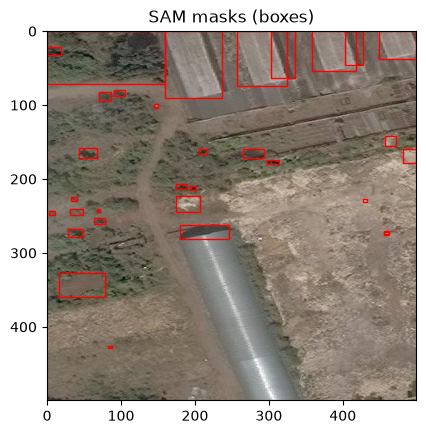

In [10]:
fig, ax = plt.subplots(1)
ax.imshow(image)
ax.set_title("SAM masks (boxes)")

for m in masks:
    x_min, y_min, width, height = m['bbox']
    rect = patches.Rectangle((x_min, y_min), width, height, linewidth=1, edgecolor='r', facecolor='none')
    ax.add_patch(rect)

plt.show()

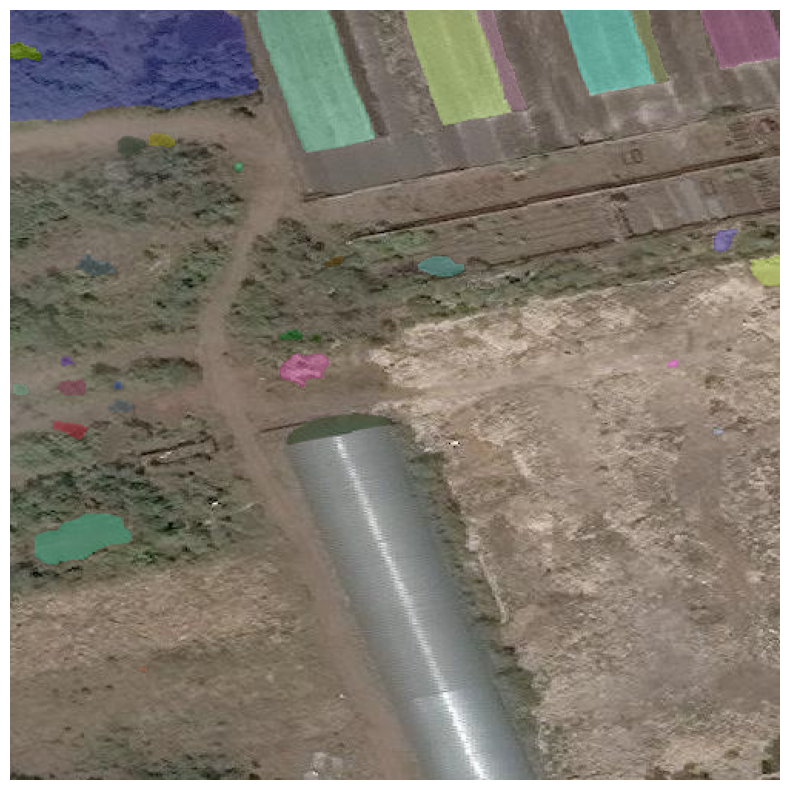

In [11]:
plt.figure(figsize=(10, 10))
plt.imshow(image)
show_anns(masks)
plt.axis('off')
plt.show()

**Which SAM masks agree with the labels?**

The Jaccard index (IoU) of two binary masks is the area of their intersection (logical AND) divided by the area of their union (logical OR). It is 1 when the masks are identical and 0 when they do not touch.

**The matching rule:** compare every SAM mask with every labelled box, with the box filled in as a rectangular mask. A SAM mask counts as a valid segment of a building when its IoU with a labelled box is **above 0.3**. The cell below shows each matching pair and counts them.

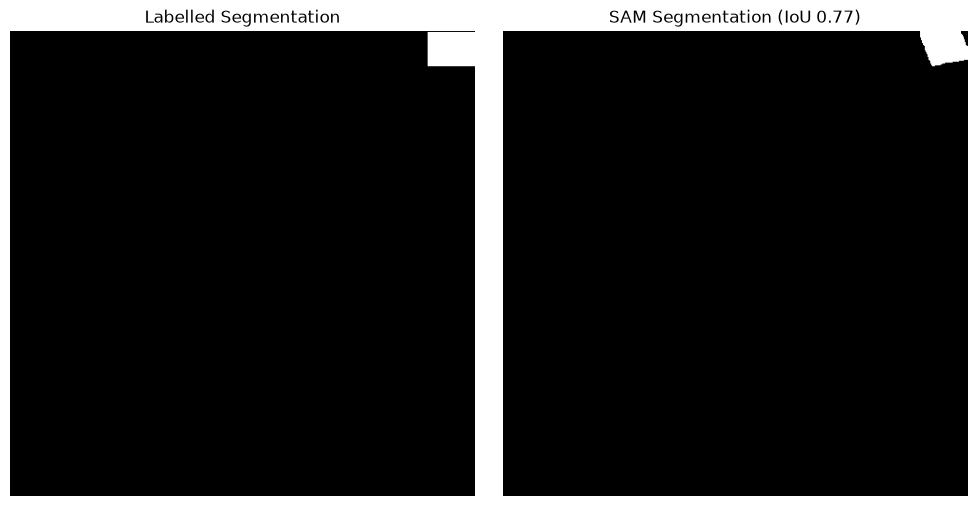

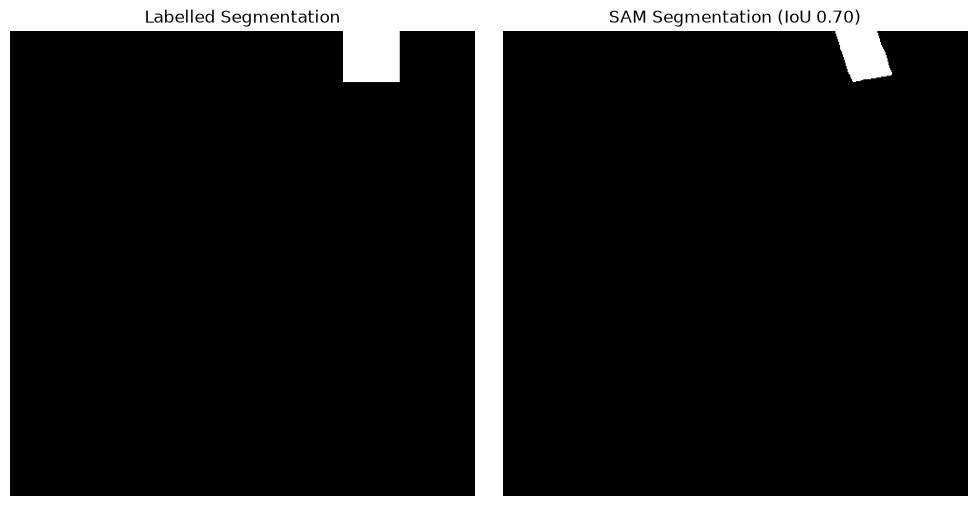

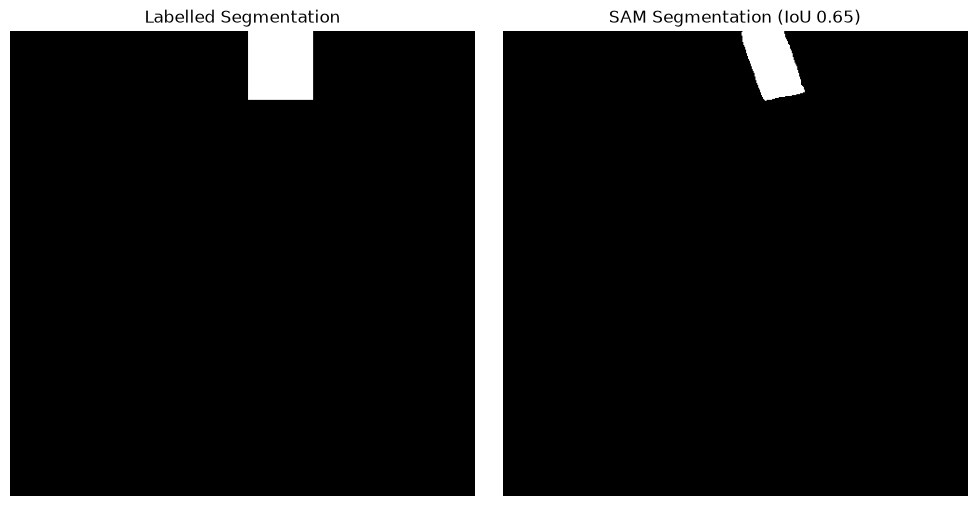

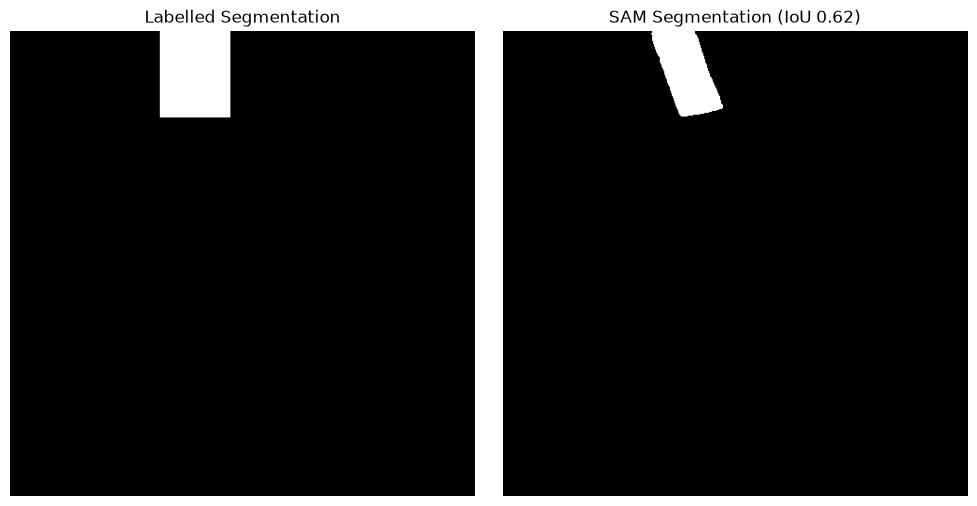

4 SAM masks match a labelled building with IoU > 0.3
They cover 4 of the 5 labelled buildings
Best IoU of any SAM mask with each labelled box: [0.7  0.77 0.02 0.62 0.65]


In [12]:
def iou(mask_a, mask_b):
    return np.sum(np.logical_and(mask_a, mask_b)) / np.sum(np.logical_or(mask_a, mask_b))


boxes = example["objects"]["bbox"]
box_masks = [make_mask(b, image) for b in boxes]
best_iou = np.zeros(len(boxes))  # the best IoU any SAM mask reaches with each labelled box
matches = 0
for sam_box in masks:
    sam_seg = sam_box['segmentation'].astype(int)
    for j, label_seg in enumerate(box_masks):
        score = iou(sam_seg, label_seg)
        best_iou[j] = max(best_iou[j], score)
        if score > 0.3:
            matches += 1
            fig, axes = plt.subplots(1, 2, figsize=(10, 5))
            axes[0].imshow(label_seg, cmap='gray')
            axes[0].set_title('Labelled Segmentation')
            axes[0].axis('off')
            axes[1].imshow(sam_seg, cmap='gray')
            axes[1].set_title(f'SAM Segmentation (IoU {score:.2f})')
            axes[1].axis('off')
            plt.tight_layout()
            plt.show()

print(f"{matches} SAM masks match a labelled building with IoU > 0.3")
print(f"They cover {np.sum(best_iou > 0.3)} of the {len(boxes)} labelled buildings")
print("Best IoU of any SAM mask with each labelled box:", np.round(best_iou, 2))

**Why so few matches?** A low count is expected.

- SAM segments everything it sees. In this image most of its masks are bushes, bare ground and the trees at the top left, and only buildings are labelled.
- The labels are rectangles. A good SAM mask follows the real outline of the roof, so an L-shaped or rotated building fills only part of its box and its IoU drops.
- SAM often splits a large building into parts of its roof. Here it outlines only the end of the long curved roof at the bottom, a small part of its box (IoU 0.02).
- In the full run (a 32x32 grid of point prompts, ViT-B), 4 of SAM's 32 masks match, and they cover 4 of the 5 labelled buildings, with IoU 0.62 to 0.77. The smoke test (an 8x8 grid) finds 3 masks, and all 3 match.
- The masks that do match are the useful output: pixel-level outlines of buildings that the labels only mark with a box. A lower threshold finds more matches, and more of them are wrong.

**Prompt SAM with the labelled boxes**

The automatic generator prompts SAM with points and keeps whatever it finds. SAM also takes a box as its prompt: give it each labelled box, and it returns one mask for the building inside it.

`SamPredictor` encodes the image once (`set_image`, the slow step), and each prompt after that takes a fraction of a second.

In [13]:
import time

from segment_anything import SamPredictor

predictor = SamPredictor(sam)
start = time.perf_counter()
predictor.set_image(np.array(image))
box_prompted = []  # one (mask, SAM's own quality score) per labelled building
for x_min, y_min, width, height in boxes:
    prompt = np.array([x_min, y_min, x_min + width, y_min + height])
    mask, score, _ = predictor.predict(box=prompt, multimask_output=False)
    box_prompted.append((mask[0], score[0]))
print(f"{len(boxes)} box prompts in {time.perf_counter() - start:.0f} s on {device}")

box_iou = np.array([iou(m, b) for (m, _), b in zip(box_prompted, box_masks)])
print("IoU of each box-prompted mask with its box:", np.round(box_iou, 2))
print("SAM's own score for each mask:", np.round([s for _, s in box_prompted], 2))

5 box prompts in 7 s on cpu
IoU of each box-prompted mask with its box: [0.7  0.78 0.46 0.61 0.65]
SAM's own score for each mask: [0.98 0.97 0.98 0.97 0.98]


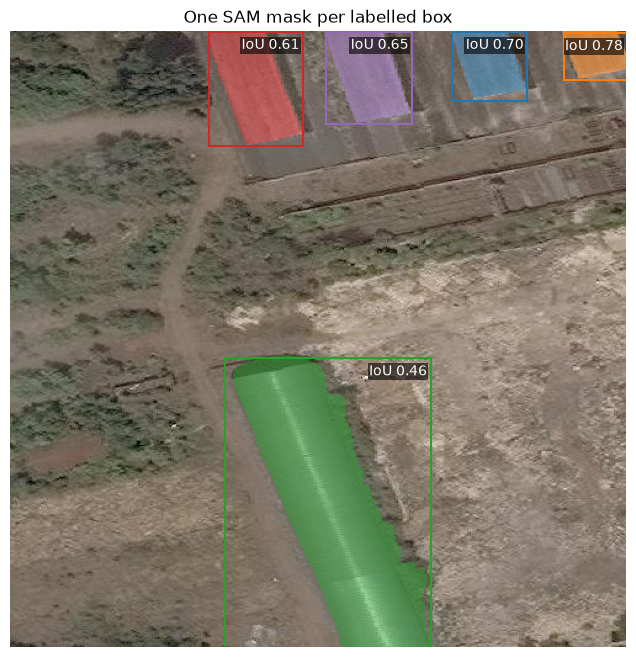

In [14]:
colours = plt.cm.tab10.colors
overlay = np.zeros((image.height, image.width, 4))
for j, (m, _) in enumerate(box_prompted):
    overlay[m] = [*colours[j % 10], 0.5]

fig, ax = plt.subplots(1, figsize=(8, 8))
ax.imshow(image)
ax.imshow(overlay)
for j, (x_min, y_min, width, height) in enumerate(boxes):
    ax.add_patch(patches.Rectangle((x_min, y_min), width, height, linewidth=1.5,
                                   edgecolor=colours[j % 10], facecolor='none'))
    ax.text(x_min + width - 3, y_min + 14, f"IoU {box_iou[j]:.2f}", color='white', fontsize=10, ha='right',
            bbox=dict(facecolor='black', alpha=0.6, pad=1, linewidth=0))
ax.set_title("One SAM mask per labelled box")
ax.axis('off')
plt.show()

**Two things to notice**

- The IoU here compares a mask with a rectangle, so it does not measure the mask's accuracy. The long curved roof at the bottom runs diagonally across its box: its mask follows the roof, and still fills less than half of the box. An L-shaped building does the same. To score the masks, compare them with masks drawn by hand.
- This is how SAM turns cheap box labels into pixel masks. A box is quick to draw. SAM fills in the outline, and a person fixes the few masks that are wrong. This is pre-labelling, and it is how tools such as Label Studio use SAM.

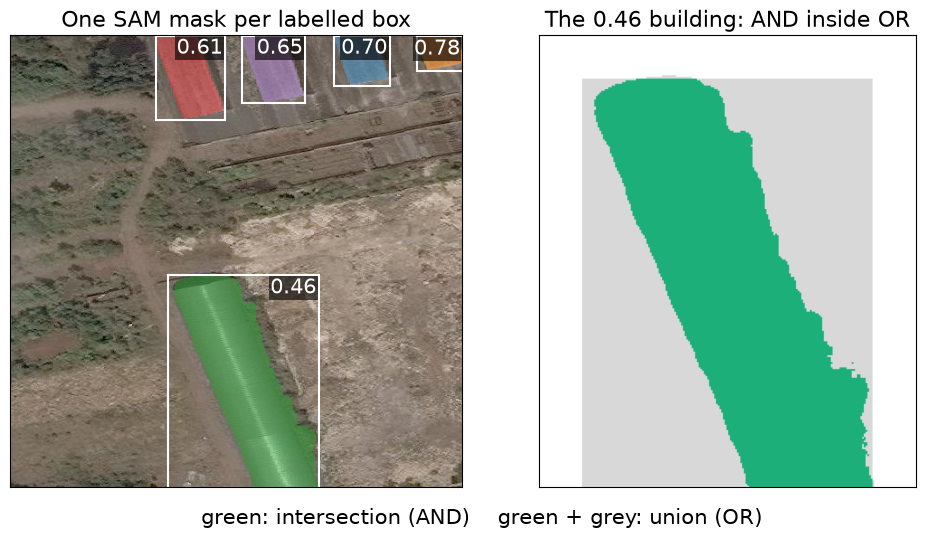

In [15]:
# The figure for the slide: every box-prompted mask, and a close-up of the building with
# the lowest IoU (labelled box, SAM mask, and their intersection inside their union)
j = int(np.argmin(box_iou))
x_min, y_min, width, height = boxes[j]
pad = 25
r0, r1 = max(int(y_min) - pad, 0), min(int(y_min + height) + pad, image.height)
c0, c1 = max(int(x_min) - pad, 0), min(int(x_min + width) + pad, image.width)
box, mask = box_masks[j][r0:r1, c0:c1] > 0, box_prompted[j][0][r0:r1, c0:c1]

fig, (left, right) = plt.subplots(1, 2, figsize=(10, 5.4))
left.imshow(image)
left.imshow(overlay)
for k, (bx, by, bw, bh) in enumerate(boxes):
    left.add_patch(patches.Rectangle((bx, by), bw, bh, linewidth=1.5, edgecolor='white', facecolor='none'))
    left.text(bx + bw - 3, by + 20, f"{box_iou[k]:.2f}", color='white', fontsize=15, ha='right',
              bbox=dict(facecolor='black', alpha=0.6, pad=1, linewidth=0))
left.set_title("One SAM mask per labelled box", fontsize=16)

both = np.ones((*box.shape, 3))
both[box | mask] = [0.85, 0.85, 0.85]  # union: grey
both[box & mask] = [0.11, 0.69, 0.48]  # intersection: green
right.imshow(both)
right.set_title(f"The {box_iou[j]:.2f} building: AND inside OR", fontsize=16)
for ax in (left, right):
    ax.set_xticks([])
    ax.set_yticks([])
fig.text(0.5, 0.02, "green: intersection (AND)    green + grey: union (OR)", ha="center", fontsize=15)
fig.tight_layout(rect=(0, 0.06, 1, 1))
fig.savefig("week7-sam-box-prompts.png", dpi=150)
plt.show()